In [1]:
#IMPORTING NECESSARY LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV


import warnings
warnings.filterwarnings("ignore")

LOAD THE DATASET

In [2]:
df=pd.read_csv("/content/usedCars.csv")

In [3]:
# to see the first five rows of the dataset
df.head()

,Id,Company,Model,Variant,FuelType,Colour,Kilometer,BodyStyle,TransmissionType,ManufactureDate,ModelYear,CngKit,Price,Owner,DealerState,DealerName,City,Warranty,QualityScore
0,555675,MARUTI SUZUKI,CELERIO(2017-2019),1.0 ZXI AMT O,PETROL,Silver,33197,HATCHBACK,NaN,2018-02-01,2018,NaN,5.75 Lakhs,1st Owner,Karnataka,Top Gear Cars,Bangalore,1,7.8
1,556383,MARUTI SUZUKI,ALTO,LXI,PETROL,Red,10322,HATCHBACK,Manual,2021-03-01,2021,NaN,4.35 Lakhs,1st Owner,Karnataka,Renew 4 u Automobiles PVT Ltd,Bangalore,1,8.3
2,556422,HYUNDAI,GRAND I10,1.2 KAPPA ASTA,PETROL,Grey,37889,HATCHBACK,Manual,2015-03-01,2015,NaN,4.7 Lakhs,1st Owner,Karnataka,Anant Cars Auto Pvt Ltd,Bangalore,1,7.9
3,556771,TATA,NEXON,XT PLUS,PETROL,A Blue,13106,HATCHBACK,NaN,2020-08-01,2020,NaN,9.9 Lakhs,1st Owner,Karnataka,Adeep Motors,Bangalore,1,8.1
4,559619,FORD,FIGO,EXI DURATORQ 1.4,DIESEL,Silver,104614,HATCHBACK,Manual,2010-11-01,2010,NaN,2.7 Lakhs,2nd Owner,Karnataka,Zippy Automart,Bangalore,0,7.5


EDA - EXPLORATORY DATA ANALYSIS

In [4]:
df.shape

(1064, 19)

In [5]:
df.columns

Index(['Id', 'Company', 'Model', 'Variant', 'FuelType', 'Colour', 'Kilometer',
       'BodyStyle', 'TransmissionType', 'ManufactureDate', 'ModelYear',
       'CngKit', 'Price', 'Owner', 'DealerState', 'DealerName', 'City',
       'Warranty', 'QualityScore'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1064 entries, 0 to 1063
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Id                1064 non-null   int64  
 1   Company           1064 non-null   object 
 2   Model             1064 non-null   object 
 3   Variant           1064 non-null   object 
 4   FuelType          1063 non-null   object 
 5   Colour            1064 non-null   object 
 6   Kilometer         1064 non-null   int64  
 7   BodyStyle         1064 non-null   object 
 8   TransmissionType  350 non-null    object 
 9   ManufactureDate   1064 non-null   object 
 10  ModelYear         1064 non-null   int64  
 11  CngKit            22 non-null     object 
 12  Price             1064 non-null   object 
 13  Owner             1064 non-null   object 
 14  DealerState       1064 non-null   object 
 15  DealerName        1064 non-null   object 
 16  City              1064 non-null   object 


In [7]:
df.describe()

,Id,Kilometer,ModelYear,Warranty,QualityScore
count,1064.000000,1064.000000,1064.000000,1064.000000,1064.000000
mean,568156.542293,52807.187970,2016.864662,0.738722,7.770207
std,16438.139974,33840.296979,2.996786,0.439538,0.719717
min,525978.000000,101.000000,2003.000000,0.000000,0.000000
25%,555321.500000,32113.500000,2015.000000,0.000000,7.500000
50%,572753.000000,49432.000000,2017.000000,1.000000,7.800000
75%,583072.750000,68828.500000,2019.000000,1.000000,8.100000
max,589122.000000,640000.000000,2023.000000,1.000000,9.400000


In [8]:
df.describe().round(2)

,Id,Kilometer,ModelYear,Warranty,QualityScore
count,1064.00,1064.00,1064.00,1064.00,1064.00
mean,568156.54,52807.19,2016.86,0.74,7.77
std,16438.14,33840.30,3.00,0.44,0.72
min,525978.00,101.00,2003.00,0.00,0.00
25%,555321.50,32113.50,2015.00,0.00,7.50
50%,572753.00,49432.00,2017.00,1.00,7.80
75%,583072.75,68828.50,2019.00,1.00,8.10
max,589122.00,640000.00,2023.00,1.00,9.40


In [9]:
# dropping ManufactureDate because we already have model year
df.drop("ManufactureDate", axis=1)

,Id,Company,Model,Variant,FuelType,Colour,Kilometer,BodyStyle,TransmissionType,ModelYear,CngKit,Price,Owner,DealerState,DealerName,City,Warranty,QualityScore
0,555675,MARUTI SUZUKI,CELERIO(2017-2019),1.0 ZXI AMT O,PETROL,Silver,33197,HATCHBACK,NaN,2018,NaN,5.75 Lakhs,1st Owner,Karnataka,Top Gear Cars,Bangalore,1,7.8
1,556383,MARUTI SUZUKI,ALTO,LXI,PETROL,Red,10322,HATCHBACK,Manual,2021,NaN,4.35 Lakhs,1st Owner,Karnataka,Renew 4 u Automobiles PVT Ltd,Bangalore,1,8.3
2,556422,HYUNDAI,GRAND I10,1.2 KAPPA ASTA,PETROL,Grey,37889,HATCHBACK,Manual,2015,NaN,4.7 Lakhs,1st Owner,Karnataka,Anant Cars Auto Pvt Ltd,Bangalore,1,7.9
3,556771,TATA,NEXON,XT PLUS,PETROL,A Blue,13106,HATCHBACK,NaN,2020,NaN,9.9 Lakhs,1st Owner,Karnataka,Adeep Motors,Bangalore,1,8.1
4,559619,FORD,FIGO,EXI DURATORQ 1.4,DIESEL,Silver,104614,HATCHBACK,Manual,2010,NaN,2.7 Lakhs,2nd Owner,Karnataka,Zippy Automart,Bangalore,0,7.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1059,588906,HYUNDAI,ELITE I20(2020-2020),ASTA O 1.2 BS VI,PETROL,White,42918,HATCHBACK,NaN,2020,NaN,7.15 Lakhs,1st Owner,Rajasthan,K.S. Motors,Jaipur,1,8.3
1060,588945,HYUNDAI,XCENT(2017-2020),S,PETROL,White,78910,SEDAN,NaN,2019,NaN,5.00 Lakhs,1st Owner,Rajasthan,Rajasthan Car World,Jaipur,0,7.8
1061,588946,MAHINDRA,SCORPIO(2009-2014),VLX 2WD BS-III,DIESEL,White,76000,SUV,NaN,2013,NaN,5.75 Lakhs,1st Owner,Rajasthan,Rajasthan Car World,Jaipur,0,6.8
1062,588949,MARUTI SUZUKI,VITARA BREZZA,VDI,DIESEL,Silver,80120,HATCHBACK,NaN,2018,NaN,7.71 Lakhs,1st Owner,Rajasthan,Rajasthan Car World,Jaipur,0,7.4


In [10]:
# for checking missing values
df.isnull().sum()

,0
Id,0
Company,0
Model,0
Variant,0
FuelType,1
Colour,0
Kilometer,0
BodyStyle,0
TransmissionType,714
ManufactureDate,0


In [11]:
# identifying how many datatypes do we have in our dataset
df.dtypes.value_counts()

,count
object,14
int64,4
float64,1


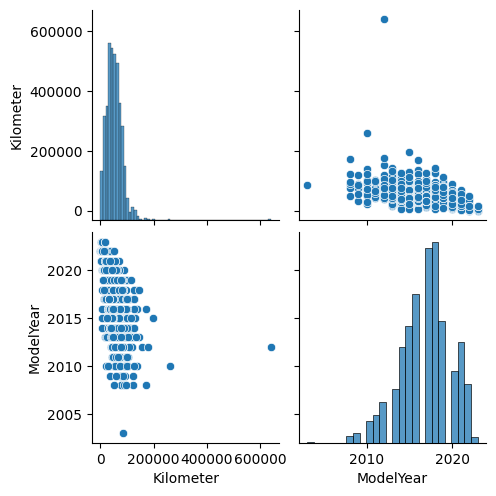

In [12]:
# Plot a pairplot to visualize relationships between numeric features
sns.pairplot(df[['Kilometer', 'ModelYear']])
plt.show()

In [13]:
# Count of each class
df.value_counts()

,,,,,,,,,,,,,,,,,,,count
Id,Company,Model,Variant,FuelType,Colour,Kilometer,BodyStyle,TransmissionType,ManufactureDate,ModelYear,CngKit,Price,Owner,DealerState,DealerName,City,Warranty,QualityScore,
534024,HYUNDAI,GRAND I10,1.2 KAPPA SPORTZ,PETROL,White,49154,HATCHBACK,Manual,2018-02-01,2018,Company Fitted,5.8 Lakhs,1st Owner,Uttar Pradesh,Heritage Expo car Sales Pvt Ltd,Noida,1,7.8,1
535644,HYUNDAI,ACCENT,EXECUTIVE,CNG,Red,55000,SEDAN,Manual,2011-05-01,2011,After Market,2.75 Lakhs,2nd Owner,Uttar Pradesh,Noida Car Ghar,Noida,0,7.0,1
551740,HYUNDAI,EON,MAGNA PLUS,LPG,Grey,60179,HATCHBACK,Manual,2014-01-01,2014,Company Fitted,3.5 Lakhs,1st Owner,Telangana,Sri Vaishnavi Cars,Hyderabad,1,7.5,1
552033,MARUTI SUZUKI,WAGON R 1.0,LXI CNG,CNG,Silver,59676,HATCHBACK,Manual,2016-05-01,2016,Company Fitted,3.64 Lakhs,1st Owner,Haryana,Prestige Autoworld Pvt Ltd,Gurgaon,1,7.7,1
556037,VOLKSWAGEN,POLO,HIGHLINE1.2L PETROL,CNG,White,66000,HATCHBACK,Manual,2012-01-01,2012,After Market,3.65 Lakhs,1st Owner,Uttar Pradesh,Adharshiya Motors,Noida,0,7.3,1
559172,HYUNDAI,I10,MAGNA 1.1 IRDE2,CNG,Grey,38000,HATCHBACK,Manual,2015-08-01,2015,After Market,3.55 Lakhs,2nd Owner,Uttar Pradesh,Noida Car Ghar,Noida,0,7.5,1
573335,MARUTI SUZUKI,WAGON R 1.0,LXI CNG,CNG,Blue,82000,HATCHBACK,Manual,2013-08-01,2013,Company Fitted,3.99 Lakhs,1st Owner,Maharashtra,OM Motors,Pune,0,6.8,1
576389,MARUTI SUZUKI,WAGON R 1.0,VXI,PETROL,White,80876,HATCHBACK,Manual,2012-10-01,2012,After Market,2.95 Lakhs,2nd Owner,Maharashtra,Car&Bike Select - Sahyadri Motors Pune,Pune,0,6.3,1
580967,MARUTI SUZUKI,WAGON R 1.0,LXI CNG,CNG,White,102197,HATCHBACK,Manual,2014-05-01,2014,Company Fitted,3.5 Lakhs,2nd Owner,Maharashtra,Car&Bike Superstore Pune,Pune,0,6.4,1


DATA PREPROCESSING

In [14]:
# Fill missing numeric values with mode
for col in df.select_dtypes(include=['object']).columns:
    most_common_value = df[col].mode()[0]
    df[col] = df[col].fillna(most_common_value)

In [15]:
# Confirm that missing values are removed
print(df.isnull().sum())

Id                  0
Company             0
Model               0
Variant             0
FuelType            0
Colour              0
Kilometer           0
BodyStyle           0
TransmissionType    0
ManufactureDate     0
ModelYear           0
CngKit              0
Price               0
Owner               0
DealerState         0
DealerName          0
City                0
Warranty            0
QualityScore        0
dtype: int64


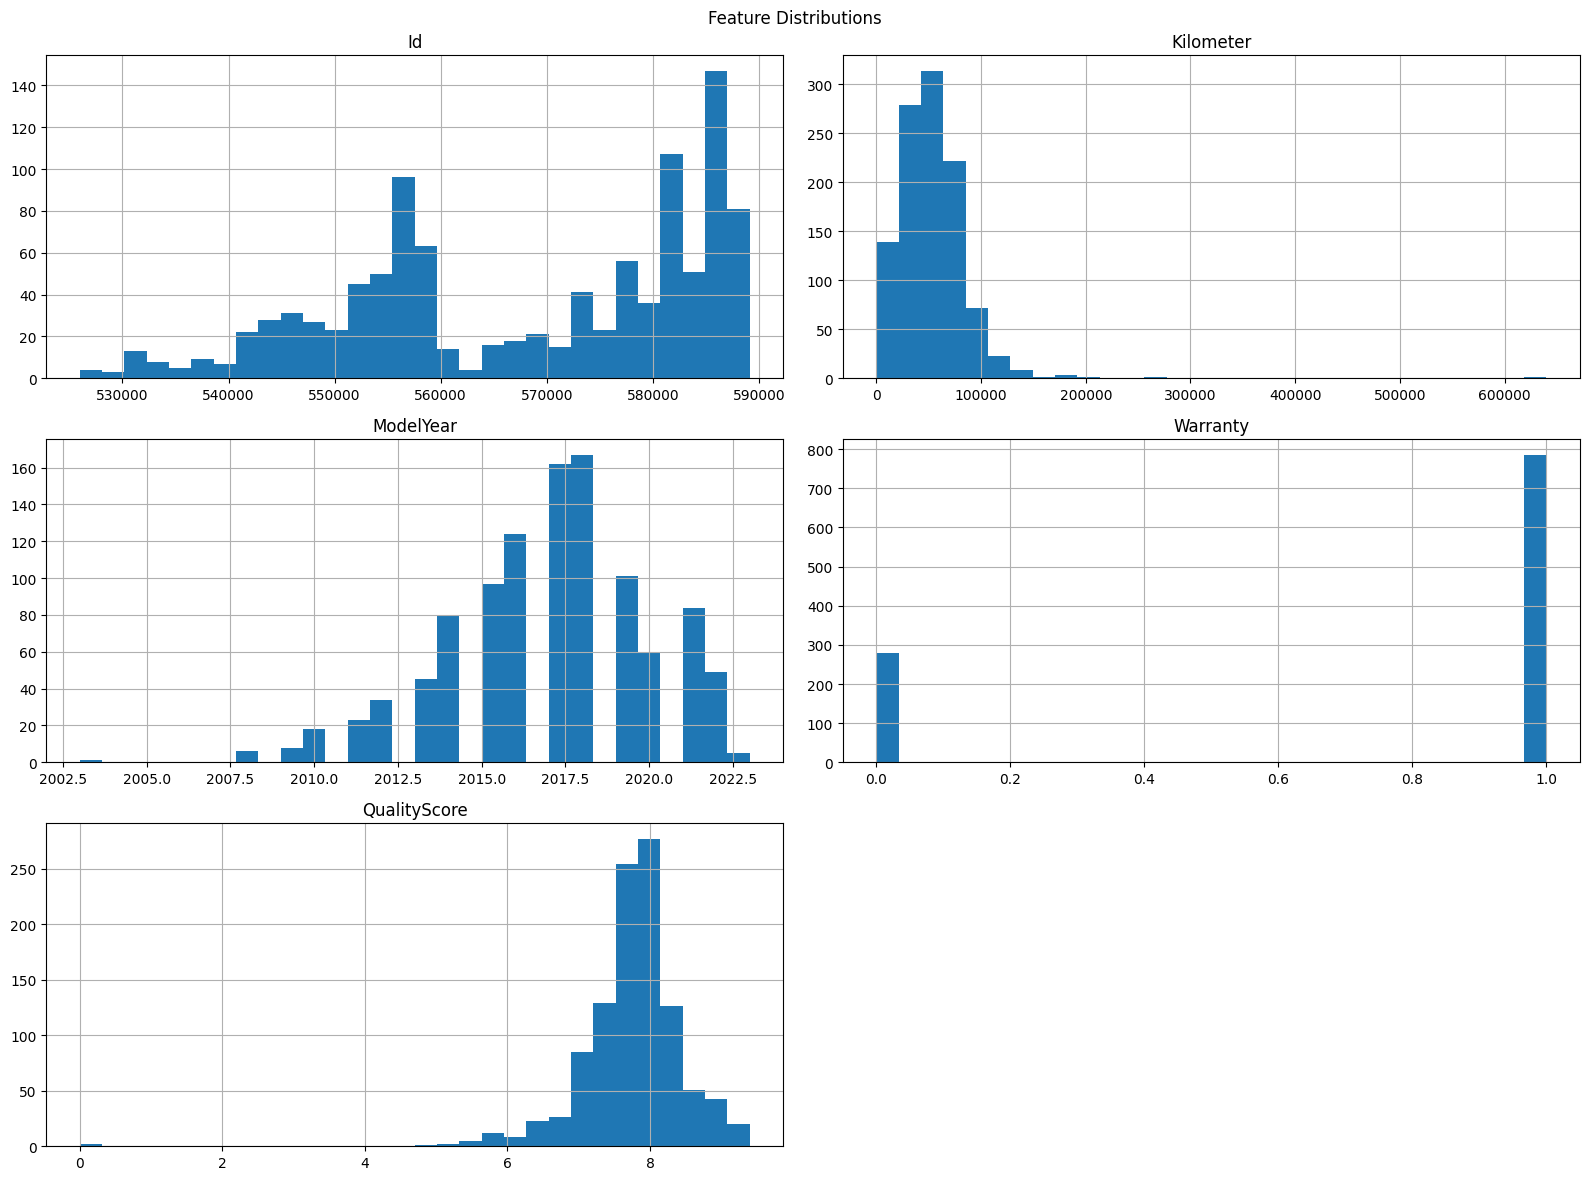

In [16]:
# to create  histograms for the numerical columns
df.hist(figsize=(16, 12), bins=30)
plt.suptitle("Feature Distributions")
plt.tight_layout()
plt.show()

In [17]:
# Select numeric columns to standardize
numeric_features = df[['Kilometer', 'ModelYear', 'Warranty', 'QualityScore']]

# Standardize the data
scaler = StandardScaler()
scaled_features = scaler.fit_transform(numeric_features)

In [18]:
# creating a Label Encoder object
encoder = LabelEncoder()

In [19]:
#Finding all text (categorical/object) columns automatically
categorical_cols = df.select_dtypes(include=['object']).columns

In [20]:
# creating a loop through each text column and then converting it to numbers
for col in categorical_cols:
    df[col] = encoder.fit_transform(df[col].astype(str))

In [21]:
print(df.head())

       Id  Company  Model  Variant  FuelType  Colour  Kilometer  BodyStyle  \
0  555675       12     34        5         4      61      33197          1   
1  556383       12     11      275         4      56      10322          1   
2  556422        7     91       10         4      34      37889          1   
3  556771       19    135      527         4       0      13106          1   
4  559619        5     83      211         1      61     104614          1   

   TransmissionType  ManufactureDate  ModelYear  CngKit  Price  Owner  \
0                 7              102       2018       1    246      0   
1                 7              138       2021       1    197      0   
2                 7               67       2015       1    209      0   
3                 7              131       2020       1    361      0   
4                 7               20       2010       1    113      1   

   DealerState  DealerName  City  Warranty  QualityScore  
0            2          52     0 

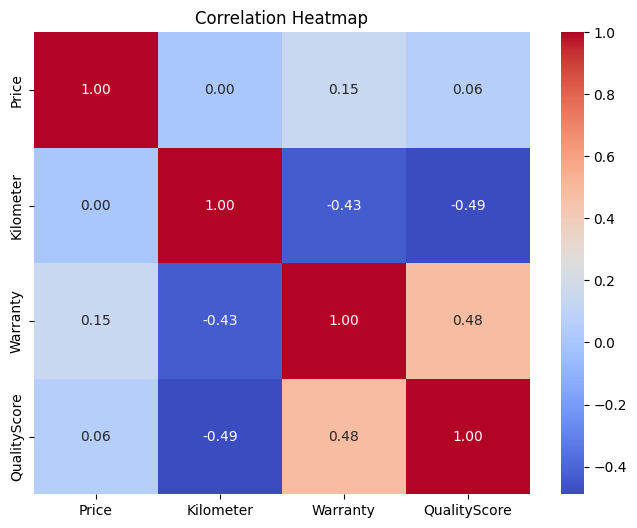

In [22]:
number_columns = ['Price', 'Kilometer', 'CarAge', 'Warranty', 'QualityScore']

# Filter to only include columns that actually exist in the DataFrame
existing_columns = [col for col in number_columns if col in df.columns]

plt.figure(figsize=(8, 6))
sns.heatmap(df[existing_columns].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

Feature Engineering

In [23]:
# Assume current year is 2026
current_year = 2026

In [24]:
# Creating a new feature: CarAge
df['CarAge'] = current_year - df['ModelYear']

In [25]:
# defining the age of first 5 cars
print(df[['ModelYear', 'CarAge']].head())

   ModelYear  CarAge
0       2018       8
1       2021       5
2       2015      11
3       2020       6
4       2010      16


In [26]:
# Defining  bins and labels for kilometers driven
bins = [0, 30000, 70000, 200000]
labels = ['Low Mileage', 'Medium Mileage', 'High Mileage']

In [27]:
# Create a new binned feature
df['MileageCategory'] = pd.cut(df['Kilometer'], bins=bins, labels=labels)

print(df[['Kilometer', 'MileageCategory']].head())

   Kilometer MileageCategory
0      33197  Medium Mileage
1      10322     Low Mileage
2      37889  Medium Mileage
3      13106     Low Mileage
4     104614    High Mileage


In [28]:
# Defining  bins and labels for kilometers driven
bins = [0, 30000, 70000, 200000]
labels = ['Low Mileage', 'Medium Mileage', 'High Mileage']

In [29]:
# Creating  a new binning  feature
# showing the first few car's kilometer with their mileage category
df['MileageCategory'] = pd.cut(df['Kilometer'], bins=bins, labels=labels)

print(df[['Kilometer', 'MileageCategory']].head())

   Kilometer MileageCategory
0      33197  Medium Mileage
1      10322     Low Mileage
2      37889  Medium Mileage
3      13106     Low Mileage
4     104614    High Mileage


In [30]:
# Converting  ManufactureDate to actual pandas datetime format
df['ManufactureDate'] = pd.to_datetime(df['ManufactureDate'])

In [31]:
# Extracting useful new features
df['Mfg_Year'] = df['ManufactureDate'].dt.year
df['Mfg_Month'] = df['ManufactureDate'].dt.month

print(df[['ManufactureDate', 'Mfg_Year', 'Mfg_Month']].head())

                ManufactureDate  Mfg_Year  Mfg_Month
0 1970-01-01 00:00:00.000000102      1970          1
1 1970-01-01 00:00:00.000000138      1970          1
2 1970-01-01 00:00:00.000000067      1970          1
3 1970-01-01 00:00:00.000000131      1970          1
4 1970-01-01 00:00:00.000000020      1970          1


In [32]:
# Removing extreme outliers using the Interquartile Range (IQR) method for 'Kilometer'
Q1 = df['Kilometer'].quantile(0.25)
Q3 = df['Kilometer'].quantile(0.75)
IQR = Q3 - Q1

In [33]:
# Keeping only the rows within a normal range
df = df[(df['Kilometer'] >= Q1 - 1.5 * IQR) & (df['Kilometer'] <= Q3 + 1.5 * IQR)]

In [34]:
# Checking for duplicates
print("Duplicate count:", df.duplicated().sum())

Duplicate count: 0


In [35]:
# Removing  duplicate rows
df = df.drop_duplicates()

In [36]:
# Separating features (X) and target/label you want to predict (y)
X = df.drop(columns=['Price'])
y = df['Price']


In [37]:
# spliting data into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [38]:
#Fiting  and transforming the training features
X_train[['Kilometer']] = scaler.fit_transform(X_train[['Kilometer']])

# 2. Transform the test features using the SAME training rules
X_test[['Kilometer']] = scaler.transform(X_test[['Kilometer']])

In [39]:
# Transforming  the test features using the SAME training rules
X_test[['Kilometer']] = scaler.transform(X_test[['Kilometer']])
print(X_train[['Kilometer']].head())

     Kilometer
98   -0.378266
650   0.692308
395  -0.019002
520  -1.671464
710   0.099247


In [40]:
# Creating a new interaction feature for the training set
X_train['Age_Mileage_Interaction'] = X_train['CarAge'] * X_train['Kilometer']

In [41]:
#Creating a new interaction feature for the testing  set
X_test['Age_Mileage_Interaction'] = X_test['CarAge'] * X_test['Kilometer']

print(X_train[['CarAge', 'Kilometer', 'Age_Mileage_Interaction']].head())

     CarAge  Kilometer  Age_Mileage_Interaction
98        7  -0.378266                -2.647863
650      13   0.692308                 8.999999
395      12  -0.019002                -0.228023
520       5  -1.671464                -8.357322
710      13   0.099247                 1.290214


MODEL SELECTION

In [42]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

In [43]:
predictions = {}
results = []

In [44]:
# Drop non-numeric columns that scikit-learn models cannot process
X_train_clean = X_train.drop(columns=['ManufactureDate', 'MileageCategory'], errors='ignore')
X_test_clean = X_test.drop(columns=['ManufactureDate', 'MileageCategory'], errors='ignore')

for name, model in models.items():
    # 1) Train the model with cleaned numerical training data
    model.fit(X_train_clean, y_train)

    # 2) Predict the prices of the test cars
    y_pred = model.predict(X_test_clean)
    predictions[name] = y_pred

    # 3) Calculate the scores
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append([name, mse, rmse, mae, r2])
    print(name, 'trained successfully!')

Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!


Performance Evaluation

In [45]:
# creating a table of the results
results_df = pd.DataFrame(results, columns=['Model', 'MSE', 'RMSE', 'MAE', 'R2 Score'])
results_df = results_df.sort_values('R2 Score', ascending=False).reset_index(drop=True)
results_df

,Model,MSE,RMSE,MAE,R2 Score
0,Random Forest,7288.653739,85.373613,62.951058,0.230354
1,Gradient Boosting,7518.501289,86.709292,65.219387,0.206083
2,Linear Regression,9773.511696,98.861073,83.635881,-0.032035
3,Decision Tree,14311.528846,119.630802,83.259615,-0.511228


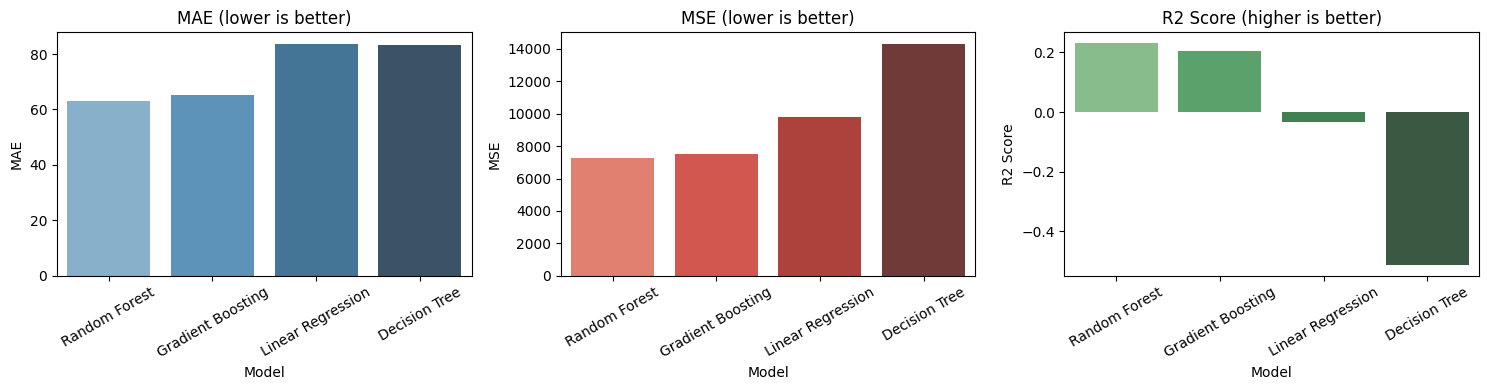

In [46]:
# preparing a graph to compare the models
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.barplot(x='Model', y='MAE', data=results_df, palette='Blues_d')
plt.title('MAE (lower is better)')
plt.xticks(rotation=30)

plt.subplot(1, 3, 2)
sns.barplot(x='Model', y='MSE', data=results_df, palette='Reds_d')
plt.title('MSE (lower is better)')
plt.xticks(rotation=30)

plt.subplot(1, 3, 3)
sns.barplot(x='Model', y='R2 Score', data=results_df, palette='Greens_d')
plt.title('R2 Score (higher is better)')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [47]:
best_model_name = results_df.loc[0, 'Model']
print('Best model:', best_model_name)
print('R2 Score  :', round(results_df.loc[0, 'R2 Score'], 3))
print('MAE       :', round(results_df.loc[0, 'MAE'], 3), 'Lakhs')

Best model: Random Forest
R2 Score  : 0.23
MAE       : 62.951 Lakhs


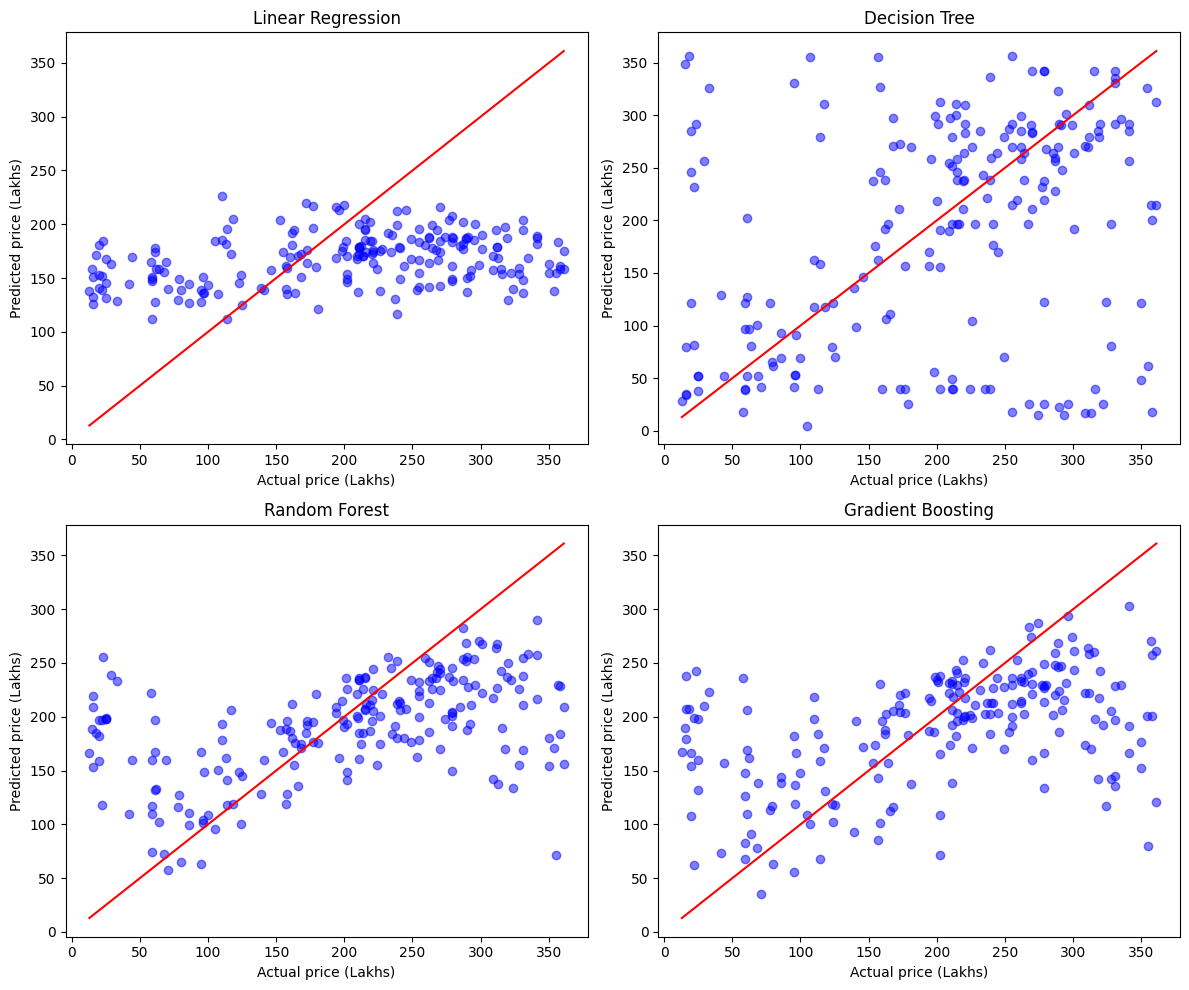

In [48]:
plt.figure(figsize=(12, 10))

i = 1
for name in predictions:
    plt.subplot(2, 2, i)
    plt.scatter(y_test, predictions[name], alpha=0.5, color='blue')
    # red line = perfect prediction
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
    plt.title(name)
    plt.xlabel('Actual price (Lakhs)')
    plt.ylabel('Predicted price (Lakhs)')
    i = i + 1

plt.tight_layout()
plt.show()

In [49]:
# improving the  model Random forest by Hyper parameter tuning

settings = {
    'n_estimators': [100, 200],       # number of trees
    'max_depth': [None, 10, 20],      # how deep each tree can go
    'min_samples_leaf': [1, 2, 4]     # minimum cars in a leaf
}

grid = GridSearchCV(RandomForestRegressor(random_state=42),
                    settings, cv=3, scoring='r2')
grid.fit(X_train_clean, y_train)

print('Best settings:', grid.best_params_)

Best settings: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 100}


In [50]:

# Testing the tuned model on the testing data
tuned_model = grid.best_estimator_
tuned_pred = tuned_model.predict(X_test_clean)

print('Tuned Random Forest results')
print('MSE      :', round(mean_squared_error(y_test, tuned_pred), 3))
print('MAE      :', round(mean_absolute_error(y_test, tuned_pred), 3), 'Lakhs')
print('R2 Score :', round(r2_score(y_test, tuned_pred), 3))

Tuned Random Forest results
MSE      : 7312.705
MAE      : 63.189 Lakhs
R2 Score : 0.228


In [51]:
# Compare real prices and predicted prices for 10 test cars
sample = pd.DataFrame({
    'Actual Price (Lakhs)': y_test.values[:10],
    'Predicted Price (Lakhs)': tuned_pred[:10].round(2)
})
sample['Difference'] = (sample['Actual Price (Lakhs)'] - sample['Predicted Price (Lakhs)']).round(2)
sample

,Actual Price (Lakhs),Predicted Price (Lakhs),Difference
0,287,252.76,34.24
1,125,155.04,-30.04
2,262,234.66,27.34
3,264,236.11,27.89
4,194,194.03,-0.03
5,235,182.89,52.11
6,23,244.45,-221.45
7,42,109.22,-67.22
8,221,207.43,13.57
9,232,257.80,-25.80
